In [ ]:
import requests #to make HTTP requests to the API
import json #to work with the JSON data returned by the API

def get_afdb_response(uniprot_id):
  """
  Fetches prediction data from the AlphaFold Database API for a given UniProt ID.

  Args:
    uniprot_id (str): The UniProt accession ID for the protein of interest. Example: "P12345"

  Returns:
    dict or str: A dictionary containing the API response (usually a list of prediction entries) if the request is successful (HTTP status code 200).
    Returns an error message string if the request fails.
  """

  AFDB_API_BASE_URL = "https://alphafold.ebi.ac.uk/api/prediction/"
  uniprot_id = uniprot_id.upper() # this will ensure that the UniProt ID is uppercase

  request_url = AFDB_API_BASE_URL + uniprot_id #construct the full URL by appending the base URL and the UniProt ID
  print(f"➡️ Sending request to: {request_url}") #to see the URL

  response = requests.get(request_url, timeout =10) #query the URL
  if response.status_code == 200: # if the request was successful (200 means OK)
    result = response.json()
    print(f"✅ Success! Received data for {uniprot_id}")
    return result

  else:
    error_message = f"❌ API request failed for {uniprot_id} with status: {response.status_code} - {response.reason}"
    print(error_message)
    if response.status_code == 404 or response.status_code == 400:
      print(f"ℹ️  Hint: A status code of 404/400 often means the UniProt ID '{uniprot_id}' is not available in the AlphaFold Database or the ID is incorrect.")


In [ ]:
uniprot_id = "Q7Z5A7" #@param {type:"string"}
get_afdb_response(uniprot_id) #call the previous function

➡️ Sending request to: https://alphafold.ebi.ac.uk/api/prediction/Q7Z5A7
✅ Success! Received data for Q7Z5A7


[{'toolUsed': 'AlphaFold Monomer v2.0 pipeline',
  'providerId': 'GDM',
  'entityType': 'protein',
  'isUniProt': True,
  'modelEntityId': 'AF-Q7Z5A7-F1',
  'modelCreatedDate': '2022-06-01T00:00:00Z',
  'sequenceVersionDate': '2008-09-02T00:00:00Z',
  'globalMetricValue': 84.48,
  'fractionPlddtVeryLow': 0.053,
  'fractionPlddtLow': 0.091,
  'fractionPlddtConfident': 0.326,
  'fractionPlddtVeryHigh': 0.53,
  'latestVersion': 4,
  'allVersions': [1, 2, 3, 4],
  'sequence': 'MAPSPRTGSRQDATALPSMSSTFWAFMILASLLIAYCSQLAAGTCEIVTLDRDSSQPRRTIARQTARCACRKGQIAGTTRARPACVDARIIKTKQWCDMLPCLEGEGCDLLINRSGWTCTQPGGRIKTTTVS',
  'sequenceStart': 1,
  'sequenceEnd': 132,
  'sequenceChecksum': '16BFE9F574FBB066',
  'isUniProtReviewed': True,
  'gene': 'TAFA5',
  'uniprotAccession': 'Q7Z5A7',
  'uniprotId': 'TAFA5_HUMAN',
  'uniprotDescription': 'Chemokine-like protein TAFA-5',
  'taxId': 9606,
  'organismScientificName': 'Homo sapiens',
  'isUniProtReferenceProteome': True,
  'bcifUrl': 'https://alphafold.ebi

In [ ]:
api_response = get_afdb_response(uniprot_id) #reuse previous function

if isinstance(api_response, list) and api_response: #check it was successful and that we have a list
  for entry in api_response:
    print(f"-- Processing Entry--")
    urls_to_download = {}

    if "cifUrl" in entry and entry["cifUrl"]:
      urls_to_download["cif"] = entry["cifUrl"]
      print(f"🔗 CIF file URL: {entry['cifUrl']}")

    if "pdbUrl" in entry and entry["pdbUrl"]:
      urls_to_download["pdbUrl"] = entry["pdbUrl"]
      print(f"🔗 PDB file URL: {entry['pdbUrl']}")

    if "paeImageUrl" in entry and entry["paeImageUrl"]:
      urls_to_download["paeImageUrl"] = entry["paeImageUrl"]
      print(f"🔗 PAE Image URL: {entry['paeImageUrl']}")

    if "amAnnotationsUrl" in entry and entry["amAnnotationsUrl"]:
      urls_to_download["amAnnotationsUrl"] = entry["amAnnotationsUrl"]
      print(f"🔗 AlphaMissense URL: {entry['amAnnotationsUrl']}")
    else:
      print("⚠️ No AlphaMissense annotations available for this entry. Is it human?")

  if not urls_to_download:
    print("No downloable URLs found in the API response.")
  else:
    print(f"Collected all urls to download: {urls_to_download}")


➡️ Sending request to: https://alphafold.ebi.ac.uk/api/prediction/Q7Z5A7
✅ Success! Received data for Q7Z5A7
-- Processing Entry--
🔗 CIF file URL: https://alphafold.ebi.ac.uk/files/AF-Q7Z5A7-F1-model_v4.cif
🔗 PDB file URL: https://alphafold.ebi.ac.uk/files/AF-Q7Z5A7-F1-model_v4.pdb
🔗 PAE Image URL: https://alphafold.ebi.ac.uk/files/AF-Q7Z5A7-F1-predicted_aligned_error_v4.png
🔗 AlphaMissense URL: https://alphafold.ebi.ac.uk/files/AF-Q7Z5A7-F1-aa-substitutions.csv
Collected all urls to download: {'cif': 'https://alphafold.ebi.ac.uk/files/AF-Q7Z5A7-F1-model_v4.cif', 'pdbUrl': 'https://alphafold.ebi.ac.uk/files/AF-Q7Z5A7-F1-model_v4.pdb', 'paeImageUrl': 'https://alphafold.ebi.ac.uk/files/AF-Q7Z5A7-F1-predicted_aligned_error_v4.png', 'amAnnotationsUrl': 'https://alphafold.ebi.ac.uk/files/AF-Q7Z5A7-F1-aa-substitutions.csv'}


In [ ]:
import os
from google.colab import drive
import re

# -- Mount Google Drive
drive.mount('/content/drive', force_remount=True) # this will mount you Google Drive

def download_files(url_dictionary):
  destination_path = "/content/drive/MyDrive/AFDB_API_course_downloads"

  if not os.path.exists(destination_path): #if the folder doesn't exist
    os.makedirs(destination_path)
    print(f"✅ Directory created: {destination_path}")
  else:
    print(f"ℹ️ Directory already exists: {destination_path}")


  for file_type, url in url_dictionary.items():
    if not url: # Skip if a URL is empty or None
        print(f"🚫 Skipping {file_type} as URL is missing.")
        continue
    try:
      original_filename = url.split('/')[-1]
      file_extension = ""
      match = re.search(r'AF-([A-Z0-9]+)-F\d+', url)
      if match:
          uniprot_id = match.group(1)

      if '.' in original_filename:
          file_extension = "." + original_filename.split('.')[-1]

      if file_type == "cif":
          filename = f"{uniprot_id}_model{file_extension or '.cif'}"
      elif file_type == "pdb":
          filename = f"{uniprot_id}_model{file_extension or '.pdb'}"
      elif file_type == "pae_image":
          filename = f"{uniprot_id}_pae{file_extension or '.png'}"
      elif file_type == "alphamissense_tsv": # Assuming you used this key earlier
          filename = f"{uniprot_id}_alphamissense{file_extension or '.tsv'}" # Or .csv if it's a csv
      else:
          # Fallback for other types: use the file_type and original extension
          filename = f"{uniprot_id}_{file_type}{file_extension}"

      full_file_path = os.path.join(destination_path, filename)

      file_response = requests.get(url, stream=True, timeout=30)

      if file_response.status_code == 200:
        with open(full_file_path, 'wb') as f:
          for chunk in file_response.iter_content(chunk_size=8192): # Download in 8KB chunks
            f.write(chunk)
        print(f"  ✅ Successfully downloaded: {filename}")
      else:
        print(f"  ❌ Failed to download {file_type}. Status: {file_response.status_code} - {file_response.reason}")

    except requests.exceptions.RequestException as e:
      print(f"  🚫 Error downloading {file_type} from {url}: {e}")
    except Exception as e:
      print(f"  🛑 An unexpected error occurred with {file_type}: {e}")
    print("-" * 20) # Separator for each file download attempt

  print("="*30 + f"\n🏁 All attempted downloads for {uniprot_id} complete.")


ValueError: mount failed

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


MessageError: Error: credential propagation was unsuccessful

In [ ]:
!fusermount -u /content/drive
!rm -rf /content/drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


fusermount: failed to unmount /content/drive: No such file or directory
Mounted at /content/drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [ ]:
import os
from google.colab import drive
import re

# -- Mount Google Drive
drive.mount('/content/drive', force_remount=True) # this will mount you Google Drive

def download_files(url_dictionary):
  destination_path = "/content/drive/MyDrive/AFDB_API_course_downloads"

  if not os.path.exists(destination_path): #if the folder doesn't exist
    os.makedirs(destination_path)
    print(f"✅ Directory created: {destination_path}")
  else:
    print(f"ℹ️ Directory already exists: {destination_path}")


  for file_type, url in url_dictionary.items():
    if not url: # Skip if a URL is empty or None
        print(f"🚫 Skipping {file_type} as URL is missing.")
        continue
    try:
      original_filename = url.split('/')[-1]
      file_extension = ""
      match = re.search(r'AF-([A-Z0-9]+)-F\d+', url)
      if match:
          uniprot_id = match.group(1)

      if '.' in original_filename:
          file_extension = "." + original_filename.split('.')[-1]

      if file_type == "cif":
          filename = f"{uniprot_id}_model{file_extension or '.cif'}"
      elif file_type == "pdb":
          filename = f"{uniprot_id}_model{file_extension or '.pdb'}"
      elif file_type == "pae_image":
          filename = f"{uniprot_id}_pae{file_extension or '.png'}"
      elif file_type == "alphamissense_tsv": # Assuming you used this key earlier
          filename = f"{uniprot_id}_alphamissense{file_extension or '.tsv'}" # Or .csv if it's a csv
      else:
          # Fallback for other types: use the file_type and original extension
          filename = f"{uniprot_id}_{file_type}{file_extension}"

      full_file_path = os.path.join(destination_path, filename)

      file_response = requests.get(url, stream=True, timeout=30)

      if file_response.status_code == 200:
        with open(full_file_path, 'wb') as f:
          for chunk in file_response.iter_content(chunk_size=8192): # Download in 8KB chunks
            f.write(chunk)
        print(f"  ✅ Successfully downloaded: {filename}")
      else:
        print(f"  ❌ Failed to download {file_type}. Status: {file_response.status_code} - {file_response.reason}")

    except requests.exceptions.RequestException as e:
      print(f"  🚫 Error downloading {file_type} from {url}: {e}")
    except Exception as e:
      print(f"  🛑 An unexpected error occurred with {file_type}: {e}")
    print("-" * 20) # Separator for each file download attempt

  print("="*30 + f"\n🏁 All attempted downloads for {uniprot_id} complete.")


Mounted at /content/drive


In [ ]:
download_files(urls_to_download)

✅ Directory created: /content/drive/MyDrive/AFDB_API_course_downloads
  ✅ Successfully downloaded: Q7Z5A7_model.cif
--------------------
  ✅ Successfully downloaded: Q7Z5A7_pdbUrl.pdb
--------------------
  ✅ Successfully downloaded: Q7Z5A7_paeImageUrl.png
--------------------
  ✅ Successfully downloaded: Q7Z5A7_amAnnotationsUrl.csv
--------------------
🏁 All attempted downloads for Q7Z5A7 complete.


In [ ]:
from google.colab import drive

#Run this code to install gemmi
!pip install gemmi

drive.mount('/content/drive', force_remount=True) # this will mount you Google Drive
destination_path = "/content/drive/MyDrive/AFDB_API_course_downloads"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 23.3 MB/s eta 0:00:00
Mounted at /content/drive


In [ ]:
import requests
import json
import gemmi

# This function is adapted from the previous Google Colab notebook to fetch data from the AlphaFold Database API.

def get_alphafold_entry_details(uniprot_id):
  """
  Fetches prediction data for a given UniProt ID from the AlphaFold Database API
  and extracts relevant URLs (cifUrl, amAnnotationsUrl).

  Args:
    uniprot_id (str): The UniProt accession ID for the protein of interest (e.g., "P12345").

  Returns:
    dict or None: A dictionary containing 'cifUrl' and 'amAnnotationsUrl' if the request
                  is successful and data is found. Returns None if the request fails
                  due to network issues, an unsuccessful status code, or no data.
  """

  AFDB_API_URL = url = f"https://alphafold.ebi.ac.uk/api/prediction/{uniprot_id}"
  try:
    print(f"Fetching data for {uniprot_id}")
    response = requests.get(AFDB_API_URL, timeout=10)
    if response.status_code == 200: # Check if the HTTP request was successful (status code 200 means OK)
        result = response.json()
        print(f"Success! Received data for {uniprot_id}")

        entry = result[0]

        return { # create a dictionary to save the data
            "cifUrl": entry["cifUrl"],
            "amAnnotationsUrl": entry["amAnnotationsUrl"],
            "pae": entry["paeDocUrl"]
        }

    else:
      print(f"⚠️ No data entries found in the API response for {uniprot_id}.")
      if response.status_code == 404 or response.status_code == 400:
        print(f"Error, please check ID for {uniprot_id}")
  except requests.exceptions.RequestException as e:
    print(f"Error fetching data for {uniprot_id}: {e}")
    return None



def _parse_plddt_from_cif(cif_url):
    """
  Downloads the mmCIF file content from the given URL and then parses
  pLDDT (Predicted Local Distance Difference Test) scores from it.
  pLDDT scores are a per-residue measure of confidence in AlphaFold's prediction.

  Args:
    cif_url (str): The URL to the mmCIF file.

  Returns:
    list: A list of dictionaries, where each dictionary contains the 'residue_number'
          and its corresponding 'plddt' score. Returns an empty list if download or parsing fails
          or no pLDDT scores are found.
    """
    plddt_scores = [] #start an empty list
    cif_content = None

    if not cif_url or cif_url.startswith("Error"):
        print("Invalid or missing CIF URL provided. Cannot download or parse pLDDT.")
        return []

    try:
        print(f"Downloading CIF content from {cif_url}...")
        cif_response = requests.get(cif_url, timeout=30) # Download the CIF file content
        if cif_response.status_code == 200:
            cif_content = cif_response.text # Get the content as a string
            print("CIF content downloaded successfully.")

        doc = gemmi.cif.read_string(cif_content)
        block = doc.sole_block()
        res_number_strs = block.find_values("_ma_qa_metric_local.label_seq_id")
        plddt_value_strs = block.find_values("_ma_qa_metric_local.metric_value")

        if not res_number_strs or not plddt_value_strs:
            print("Could not find pLDDT tags or valued in CIF")
            return []

        if len(res_number_strs) != len(plddt_value_strs):
            print(f"Mismatch in length of residues ({len(res_number_strs)}) and pLDDT values ({len(plddt_value_strs)})")
            return []

        for res_number_strs, plddt_str in zip(res_number_strs, plddt_value_strs):
            try:
                plddt_scores.append({
                    "residue_number": int(res_number_strs),
                    "plddt": float(plddt_str)
                })
            except ValueError as e_val:
                print("e_val")

        if not plddt_scores:
            print("No pLDDT scores found")
            return []

    except Exception as e:
        print(f"Error parsing CIF: {e}")
    return plddt_scores

In [ ]:
uniprot_id = "Q7Z5A7" #@param{type:"string"}
uniprot_id = uniprot_id.upper()

#@markdown **Note**: Re-run this code block and the ones below if you modify the UniProt ID

In [ ]:
# -- Example with printed plddt scores
entry_details = get_alphafold_entry_details(uniprot_id)
cif_url = entry_details.get("cifUrl")
plddt_scores = _parse_plddt_from_cif(cif_url)
print(plddt_scores)

Fetching data for Q7Z5A7
Success! Received data for Q7Z5A7
CIF content downloaded successfully.
[{'residue_number': 1, 'plddt': 42.23}, {'residue_number': 2, 'plddt': 52.09}, {'residue_number': 3, 'plddt': 52.45}, {'residue_number': 4, 'plddt': 50.31}, {'residue_number': 5, 'plddt': 59.32}, {'residue_number': 6, 'plddt': 50.59}, {'residue_number': 7, 'plddt': 47.07}, {'residue_number': 8, 'plddt': 42.66}, {'residue_number': 9, 'plddt': 48.72}, {'residue_number': 10, 'plddt': 46.9}, {'residue_number': 11, 'plddt': 51.57}, {'residue_number': 12, 'plddt': 45.78}, {'residue_number': 13, 'plddt': 51.39}, {'residue_number': 14, 'plddt': 54.17}, {'residue_number': 15, 'plddt': 49.26}, {'residue_number': 16, 'plddt': 57.52}, {'residue_number': 17, 'plddt': 56.54}, {'residue_number': 18, 'plddt': 67.09}, {'residue_number': 19, 'plddt': 67.73}, {'residue_number': 20, 'plddt': 80.83}, {'residue_number': 21, 'plddt': 80.36}, {'residue_number': 22, 'plddt': 83.46}, {'residue_number': 23, 'plddt': 8

In [ ]:
# Calculate statistics
plddt_values_only = [item['plddt'] for item in plddt_scores]
min_plddt = min(plddt_values_only)
max_plddt = max(plddt_values_only)
average_plddt = sum(plddt_values_only) / len(plddt_values_only)

print(f"\n--- pLDDT Statistics for {uniprot_id} ---")
print(f"Minimum pLDDT: {min_plddt:.2f}")
print(f"Maximum pLDDT: {max_plddt:.2f}")
print(f"Average pLDDT: {average_plddt:.2f}")


--- pLDDT Statistics for Q7Z5A7 ---
Minimum pLDDT: 42.23
Maximum pLDDT: 97.39
Average pLDDT: 84.48


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import os
from matplotlib.patches import Rectangle # Used to draw rectangular patches on a plot

def plot_plddt(plddt_data, output_path, file_name):
    """
    Plots pLDDT scores along the protein sequence with background confidence regions
    and saves the plot to a specified file.

    Parameters:
    - plddt_data (list of dict): A list of dictionaries, where each dictionary
                                 contains 'residue_number' and 'plddt' score.
                                 Example: [{'residue_number': 1, 'plddt': 85.2}, ...]
    - output_path (str): The directory where the plot image will be saved.
    - file_name (str): The base name for the output plot file (e.g., "Q5VSL9").
    """
    # Extract residue numbers and pLDDT values from the list of dictionaries
    residue_numbers = [item['residue_number'] for item in plddt_data]
    plddt_values = [item['plddt'] for item in plddt_data]

    # Create the plot figure and axes
    fig, ax = plt.subplots(figsize=(12, 5)) # Set figure size for better readability

    # Define pLDDT confidence regions as rectangles in the background
    total_residues = len(plddt_values) # The total length of the protein sequence

    # Very high confidence region (pLDDT > 90) - Dark Blue
    ax.add_patch(Rectangle((0, 90), total_residues, 10, color="#024fcc", alpha=0.3, label="Very high (pLDDT > 90)"))
    # Confident region (70 < pLDDT <= 90) - Light Blue
    ax.add_patch(Rectangle((0, 70), total_residues, 20, color="#60c2e8", alpha=0.3, label="Confident (70 < pLDDT <= 90)"))
    # Low confidence region (50 < pLDDT <= 70) - Yellow
    ax.add_patch(Rectangle((0, 50), total_residues, 20, color="#f9d613", alpha=0.3, label="Low (50 < pLDDT <= 70)"))
    # Very low confidence region (pLDDT <= 50) - Orange
    ax.add_patch(Rectangle((0, 0), total_residues, 50, color="#FF7D45", alpha=0.3, label="Very low (pLDDT <= 50)"))

    # Plot the pLDDT scores as a line plot
    # x-axis: residue numbers, y-axis: pLDDT values
    sns.lineplot(x=residue_numbers, y=plddt_values, ax=ax, color="black", linewidth=1.0)

    ax.set_xlabel('Residue Number', fontsize=12)
    ax.set_ylabel('pLDDT Score', fontsize=12)
    ax.set_title(f'Predicted Local Distance Difference Test (pLDDT) Scores for {file_name}', fontsize=14)
    ax.spines[["right", "top"]].set_visible(False) # Hide the top and right plot borders

    ax.set_xlim(min(residue_numbers) - 1, max(residue_numbers) + 1)
    ax.set_ylim(0, 100)
    ax.margins(x=0.01)

    # Add legend to explain confidence regions
    ax.legend(title="pLDDT Confidence", loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0.)

    # Create the output directory if it doesn't exist
    os.makedirs(output_path, exist_ok=True)

    # Save the plot to a file
    output_file = os.path.join(output_path, f"{file_name}_pLDDT.png")
    plt.savefig(output_file, dpi=300, bbox_inches='tight')
    print(f"pLDDT plot saved to {output_file}")
    plt.show()
    plt.close(fig)

pLDDT plot saved to /content/drive/MyDrive/AFDB_API_course_downloads/Q7Z5A7_pLDDT.png


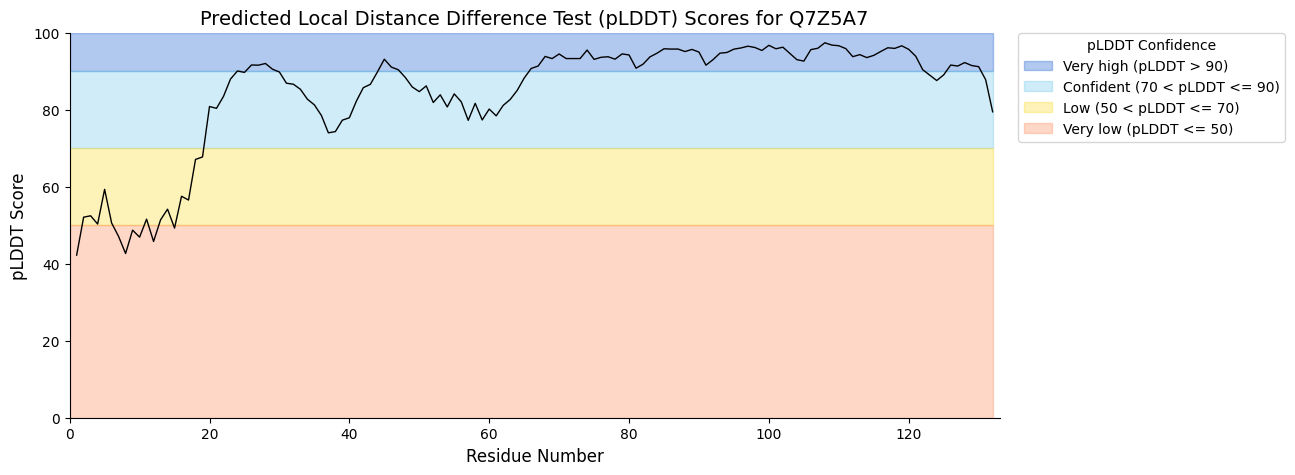

In [ ]:
# -- Mount Google Drive
plot_plddt(plddt_scores, destination_path, uniprot_id)

The maximum PAE value calculated is: 31


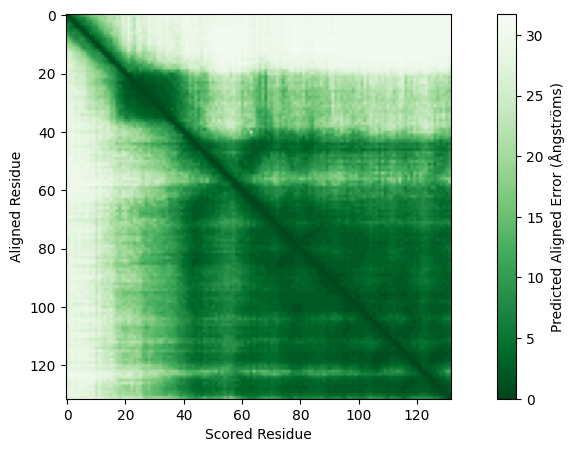

In [ ]:
import numpy as np

pae_data = entry_details.get("pae")
pae= requests.get(pae_data, timeout=30)
if pae.status_code == 200:
          pae_content = json.loads(pae.text)

pae_matrix = np.array(pae_content[0]["predicted_aligned_error"])

max_pae_calculated = np.max(pae_matrix)
print(f"The maximum PAE value calculated is: {max_pae_calculated}")

# plotting
plt.figure(figsize=(12, 5))
plt.imshow(pae_matrix, cmap="Greens_r", vmin=0, vmax=31.75)
plt.colorbar(label="Predicted Aligned Error (Ångströms)")
plt.xlabel("Scored Residue")
plt.ylabel("Aligned Residue")
plt.savefig(os.path.join(destination_path, f"{uniprot_id}_PAE.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()


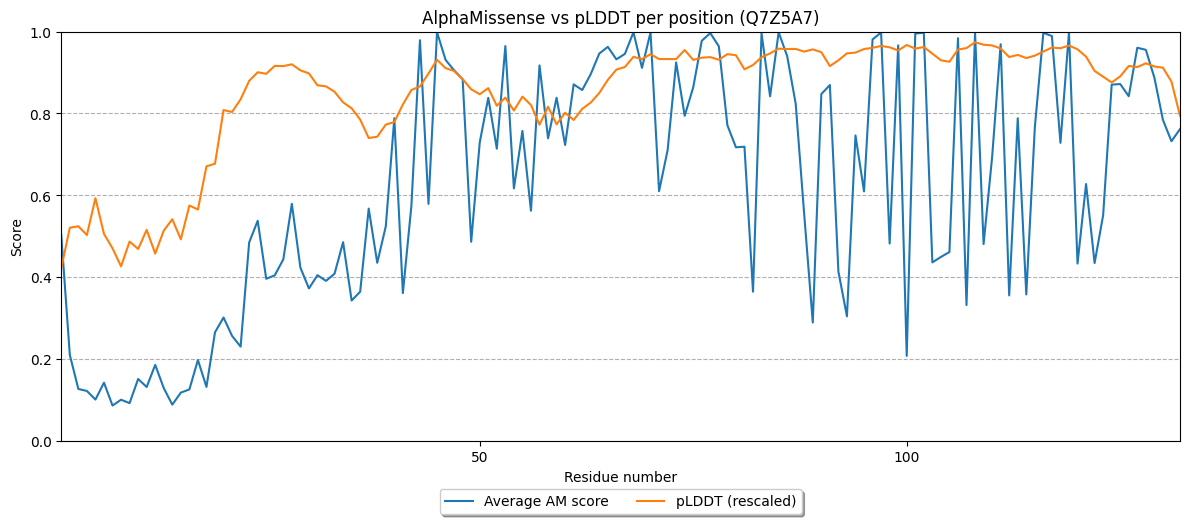

In [ ]:
import pandas as pd
import logging
import matplotlib.ticker as ticker

am_data = entry_details.get("amAnnotationsUrl")
am_response = requests.get(am_data, timeout=30)
if am_response.status_code == 200:
          am_content = pd.read_csv(am_data)

          reference_aa = am_content["protein_variant"].str.extract(r'^([A-Z])')[0]
          alternative_aa = am_content["protein_variant"].str.extract('([A-Z])$')[0]
          residue_number = pd.to_numeric(am_content["protein_variant"].str.extract(r'([0-9]+)')[0])
          pathogenicity_score = pd.to_numeric(am_content['am_pathogenicity'])

          am_data = pd.DataFrame({
              "reference_aa": reference_aa,
              "alternative_aa": alternative_aa,
              "residue_number": residue_number,
              "pathogenicity_score": pathogenicity_score
          })



def calculate_average_pathogenicity(am_data):
    """Calculates average pathogenicity scores per residue from AlphaMissense data.

    Args:
        am_data (pandas.DataFrame): DataFrame containing AlphaMissense data.
        Returns:
        numpy.ndarray or None: Array of average pathogenicity scores, or None on error.
    """
    if am_data is None:
        logging.error("No AlphaMissense data available, check if UniProt has AlphaMissense data.")
        return None

    grouped = am_data.groupby(['residue_number'])['pathogenicity_score'].mean().reset_index()
    residue_to_score = dict(zip(grouped['residue_number'], grouped['pathogenicity_score']))
    return residue_to_score



def plot_scores(plddt_scores, residue_to_score, uniprot_id):
    """
    Plots aligned pLDDT and AlphaMissense average scores per residue.

    Args:
        plddt_scores (list): List of dicts with 'residue_number' and 'plddt'.
        residue_to_score (dict): Dict mapping residue_number to average pathogenicity score.
        uniprot_id (str): Protein identifier.
    """

    residue_numbers = [entry['residue_number'] for entry in plddt_scores]
    plddt_values = [entry['plddt'] / 100.0 for entry in plddt_scores]  # Rescale to 0–1
    am_scores = [round(residue_to_score.get(res, float('nan')), 4) for res in residue_numbers]

    # Construct DataFrame
    df = pd.DataFrame({
        'Residue number': residue_numbers,
        'Average AM score': am_scores,
        'pLDDT (rescaled)': plddt_values
    })

    # Plot
    plt.figure(figsize=(12, 6))
    ax = plt.subplot(111)
    sns.lineplot(x='Residue number', y='Average AM score', data=df, label='Average AM score')
    sns.lineplot(x='Residue number', y='pLDDT (rescaled)', data=df, label='pLDDT (rescaled)')

    plt.xlabel('Residue number')
    plt.ylabel('Score')
    plt.title(f'AlphaMissense vs pLDDT per position ({uniprot_id})')
    plt.ylim(0, 1)
    plt.xlim(df['Residue number'].min(), df['Residue number'].max())

    if len(df) > 200:
        ax.xaxis.set_major_locator(ticker.MultipleLocator(100))
    else:
        ax.xaxis.set_major_locator(ticker.MultipleLocator(50))

    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), fancybox=True, shadow=True, ncol=5)
    plt.grid(axis='y', linestyle='--')
    plt.tight_layout(rect=[0, 0.1, 1, 1])

    plt.savefig(os.path.join(destination_path, f"{uniprot_id}_graph_plDDT-AM-score.png"), dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()


# get scores and plot
average_scores_am=calculate_average_pathogenicity(am_data)
plot_scores(plddt_scores, average_scores_am, uniprot_id)